# 1. Imports & Setup

In [1]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, f1_score
from sklearn.preprocessing import FunctionTransformer

# 2. Data Loading

In [2]:
train_df = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/train.csv")
test_df = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/test.csv")
sample_sub = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/Sample.csv")


print(f"Training dataset shape: {train_df.shape}")
print(f"Test dataset shape: {test_df.shape}")

Training dataset shape: (198000, 15)
Test dataset shape: (102000, 14)


# 3. Exploratory Data Analysis

```
Columns Description

comment : The raw text content of the comment.

created_date : The date and time when the comment was posted.

post_id : A unique identifier linking the comment to a discussion thread or parent post.

emoticon_1 : Indicator for the presence of symbols from the first internal emoticon group.

emoticon_2 : Indicator for the presence of symbols from the second internal emoticon group.

emoticon_3 : Indicator for the presence of symbols from the third internal emoticon group.

upvote : Number of positive reactions received by the comment.

downvote : Number of negative reactions received by the comment.

if_1 : Internal feature one that is hidden by the platform.

if_2 : Internal feature two that is hidden by the platform.

race : Indicator showing whether the system detected references to a specific group identity.

religion : Indicator showing whether the system detected references to a belief-related topic.

gender : Indicator showing whether the system detected references to a gender-related topic.

disability : Indicator showing whether the system detected references to an ability-related topic.

label : The final category assigned to the comment by the platform (Target Variable). This variable can take four distinct values, each corresponding to a different internal handling category.
```

## 3.1 Basic inspection

In [3]:
train_df.head(3)

,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
0,2024-01-18 08:43:57.397508+00:00,73,0,0,0,0,1,0,10,NaN,NaN,NaN,False,She might be a bright spot for a party keou on...,2
1,2024-03-24 21:43:11.490017+00:00,39,0,0,0,6,0,0,4,NaN,NaN,NaN,False,"Under Alaska law, a non-tribal member is not b...",0
2,2024-04-24 20:32:17.014931+00:00,31,0,1,1,0,0,0,10,NaN,NaN,NaN,False,in the future please spare me your strawman dr...,2


In [4]:
train_df.info()

"""
Here we see some null values in the following columns:
1. race
2. religion
3. gender
4. comment
"""

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   created_date  198000 non-null  object
 1   post_id       198000 non-null  int64 
 2   emoticon_1    198000 non-null  int64 
 3   emoticon_2    198000 non-null  int64 
 4   emoticon_3    198000 non-null  int64 
 5   upvote        198000 non-null  int64 
 6   downvote      198000 non-null  int64 
 7   if_1          198000 non-null  int64 
 8   if_2          198000 non-null  int64 
 9   race          52577 non-null   object
 10  religion      52577 non-null   object
 11  gender        52577 non-null   object
 12  disability    198000 non-null  bool  
 13  comment       197999 non-null  object
 14  label         198000 non-null  int64 
dtypes: bool(1), int64(9), object(5)
memory usage: 21.3+ MB


'\nHere we see some null values in the following columns:\n1. race\n2. religion\n3. gender\n4. comment\n'

In [5]:
train_df.isnull().sum()

created_date         0
post_id              0
emoticon_1           0
emoticon_2           0
emoticon_3           0
upvote               0
downvote             0
if_1                 0
if_2                 0
race            145423
religion        145423
gender          145423
disability           0
comment              1
label                0
dtype: int64

In [6]:
train_df[['emoticon_1','emoticon_2','emoticon_3','upvote','downvote','if_1','if_2']].describe()

,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2
count,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000
mean,0.279768,0.048338,0.121071,2.607975,0.666394,1.906152,7.956212
std,1.023234,0.258477,0.481013,5.054763,2.044335,25.635752,14.839464
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000
50%,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,6.000000
75%,0.000000,0.000000,0.000000,3.000000,1.000000,4.000000,10.000000
max,47.000000,11.000000,17.000000,201.000000,107.000000,1860.000000,1833.000000


## 3.2 Unique values for important columns

In [7]:
"""
Unique values of different columns to understand what they are being used for.
"""

cols_n = ['emoticon_1', 'emoticon_2', 'emoticon_3',
       'if_1', 'if_2', 'race', 'religion', 'gender',
       'disability', 'label']

for col in cols_n:
    print("="*100)
    print(f"Column: {col}")
    print(f"Number of unique values: {train_df[col].nunique()}")
    print(f"Missing values: {train_df[col].isnull().sum()}")
    print("Unique values:")
    print(train_df[col].unique())
    print("\n")

print("="*100)
print("Column: comment")
print(f"Number of unique values: {train_df['comment'].nunique()}")
print(f"Missing values: {train_df['comment'].isnull().sum()}")
print("\n")

Column: emoticon_1
Number of unique values: 36
Missing values: 0
Unique values:
[ 0  1 15  2  3  4  5 11  6  7  8 24 12 17 14 13  9 10 20 16 25 18 21 19
 23 36 22 28 27 33 30 46 32 47 31 39]


Column: emoticon_2
Number of unique values: 10
Missing values: 0
Unique values:
[ 0  1  2  4  3  5  8  6 11  7]


Column: emoticon_3
Number of unique values: 16
Missing values: 0
Unique values:
[ 0  1  2  4  3  6  5 10  7 11  9 14 17 13  8 12]


Column: if_1
Number of unique values: 57
Missing values: 0
Unique values:
[   0    6    4    5   10    7    9 1800 1569 1538   12   11 1814  249
  250 1815 1560 1263 1545 1267 1258 1543 1277 1830 1585    8 1257 1807
 1810 1783 1777 1848 1548 1232 1572 1583 1576 1256 1566 1547 1551 1825
 1271 1838 1553 1846 1558 1557 1767 1819 1581 1254 1811 1860 1778 1827
 1584]


Column: if_2
Number of unique values: 81
Missing values: 0
Unique values:
[  10    4    6   60   73   52    5   54   70   55   66   62   64   59
   76   38   57   65   80    9   69   11   53   7

## 3.3 Missing value analysis

### Missing Value Analysis – Identity Features

The columns `race`, `religion`, and `gender` contain 145,423 missing values each, which is a significant proportion of the dataset.

Each of these columns also contains an explicit category `'none'`, which indicates that the comment does not reference any identity group.

Since `'none'` is already a valid category, the `NaN` values cannot be interpreted as `'none'`. Instead, `NaN` likely represents missing or unrecorded information.

To preserve semantic distinction:
- `'none'` → Explicit absence of identity reference
- `NaN` → Missing information

Therefore, we will replace `NaN` values in:
- `race`
- `religion`
- `gender`

with a new category: `'unknown'`.

This allows the model to distinguish between:
- No identity reference (`none`)
- Missing identity metadata (`unknown`)

### Missing Value Analysis – Comment Column

The `comment` column contains only 1 missing value.

Since this is a text feature and models like TF-IDF cannot process `NaN` values, we will replace the missing value with an empty string (`""`).

This ensures:
- No loss of data
- No distortion of feature space
- Consistent preprocessing for text vectorization

In [8]:
"""
Row with nan value in comment column
"""

train_df[train_df['comment'].isna()]

,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
99535,2024-04-18 06:40:48.161601+00:00,31,0,0,0,1,0,4,4,none,none,none,False,NaN,0


In [9]:
test_df.isna().sum()


# We don't have any missing values in the comment column here.


created_date        0
post_id             0
emoticon_1          0
emoticon_2          0
emoticon_3          0
upvote              0
downvote            0
if_1                0
if_2                0
race            75269
religion        75269
gender          75269
disability          0
comment             0
dtype: int64

## 3.4 Visualization

### 3.4.1 Target distribution

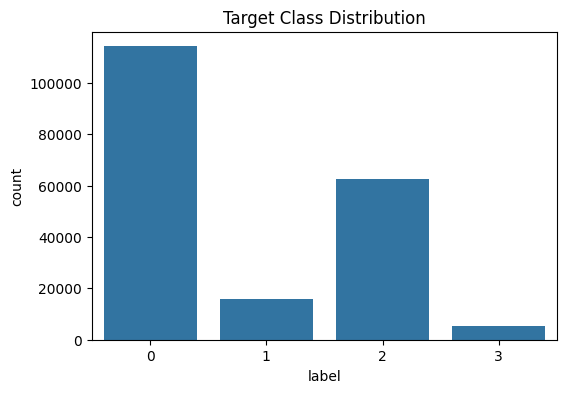

label
0    57.663131
2    31.535354
1     8.039394
3     2.762121
Name: proportion, dtype: float64

In [10]:
plt.figure(figsize=(6,4))
sns.countplot(x="label", data=train_df)
plt.title("Target Class Distribution")
plt.show()

train_df["label"].value_counts(normalize=True) * 100
# normalize=true returns the proportions instead of value counts so we can check the percentage of different labels.


#### Target Distribution Analysis

The dataset is highly imbalanced.

- Class 0 represents approximately 57.66% of the data.
- Class 2 represents 31.53%.
- Class 1 represents 8.03%.
- Class 3 represents only 2.76%.

This indicates a strong class imbalance problem, especially for class 3.

### 3.4.2 Comment Length analysis

In [11]:
train_df["comment_length"] = train_df["comment"].astype(str).apply(len)

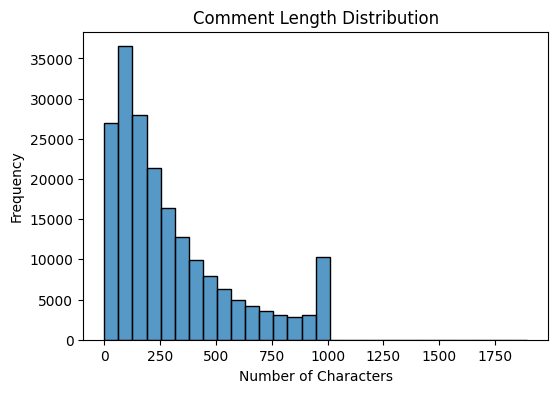

In [12]:
plt.figure(figsize=(6,4))

sns.histplot(train_df["comment_length"], bins=30)

plt.title("Comment Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.show()

#### Comment Length Analysis

The comment length distribution is heavily right-skewed.

- Most comments fall within the range of 0–300 characters.
- The distribution shows a long tail extending up to 1892 characters.
- A small number of comments are significantly longer than average.

In [13]:
"""Longest comment"""

# train_df[train_df["comment_length"] == train_df["comment_length"].max()]

train_df.loc[147495].comment

"As usual WW plumbing the depths for deeper meaning .... that is unless it involves an issue on which they disagree then it is ridicule 24/7.   Clever creating the Bundyland series complete with cartoon banner.  Set the tone for the level of journalism to expect ... journalism ?  ... fatastisticism. \n\nI did notice you soft pedaling the ridicule of David Fry identifying him as troubled.  My guess is that has more to do with sympathy for his pot smoking withdrawl rants than respect for his politics.  Respect is never a factor with liberals as evidenced by your series of vapid caricatures.  \n\nDid you happen to see the stories actual journalists did on Refuge mis-managment, fires, floods, and the millions of Carp that are harassing the birds away from the Bird Refuge?  The stories of arbitrary miss-management that are driving unemployment ever higher in eastern Oregon.  Curry County Sheriff turning in his badge in frustration for lack of resources dud to dwindling tax base engineered b

In [14]:
train_df["comment_length"].describe()

count    198000.000000
mean        302.909379
std         266.441732
min           1.000000
25%         102.000000
50%         211.000000
75%         419.000000
max        1892.000000
Name: comment_length, dtype: float64

#### Comment Length Analysis

The comment length distribution is heavily right-skewed.

- Mean length: ~303 characters
- Median length: 211 characters
- 75% of comments are under 419 characters
- Maximum length observed: 1892 characters

The significant difference between the mean and median confirms a long-tail distribution.

Note:- The comment with `nan` value was essentially turned into "nan", so it is counted as 1 word instead of 0 words.

### 3.4.3 Word Count distribution

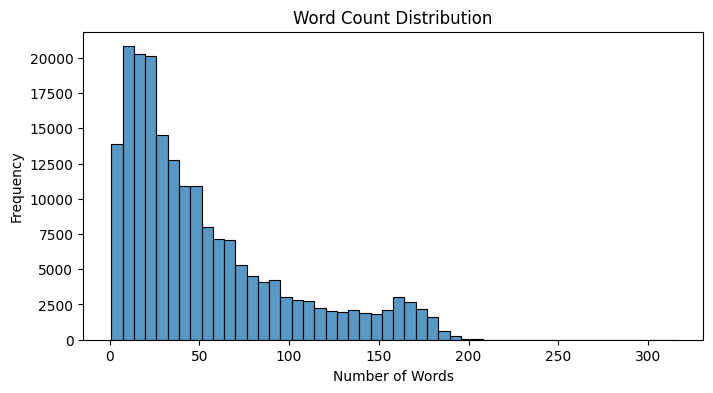

count    198000.000000
mean         52.396990
std          45.770215
min           1.000000
25%          18.000000
50%          37.000000
75%          73.000000
max         315.000000
Name: word_count, dtype: float64

In [15]:
train_df["word_count"] = train_df["comment"].astype(str).apply(lambda x: len(x.split()))

plt.figure(figsize=(8,4))
sns.histplot(train_df["word_count"], bins=50)
plt.title("Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

train_df["word_count"].describe()

#### Word Count Analysis

The word count distribution is also right-skewed.

- Mean word count: ~52 words
- Median word count: 37 words
- 75% of comments contain fewer than 73 words
- Maximum observed word count: 315 words

This confirms that most comments are relatively short, with a small number of longer discussions forming a long tail.

Note:- The comment with `nan` value was essentially turned into "nan", so it is counted as 1 word instead of 0 words.

### 3.4.4 Numerical Features Analysis

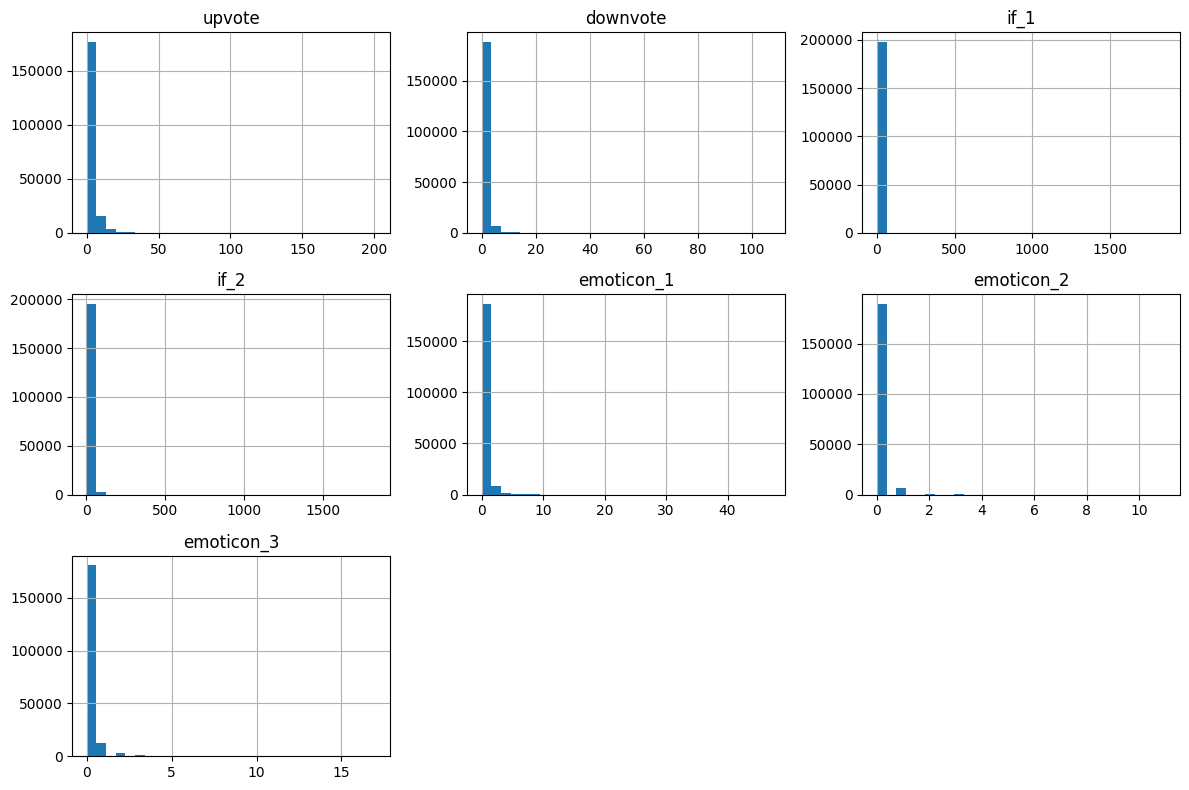

In [16]:
numeric_cols = [
    "upvote", "downvote",
    "if_1", "if_2",
    "emoticon_1", "emoticon_2", "emoticon_3"
]

train_df[numeric_cols].hist(figsize=(12,8), bins=30)
plt.tight_layout()
plt.show()

#### Numerical Feature Distribution Analysis

All numerical features exhibit strong right-skewed distributions with a large concentration of values at 0.

Observations:

- `upvote` and `downvote` are heavily skewed, with most values equal to zero.
- `if_1` and `if_2` show similar sparsity, with a few extreme high values.
- `emoticon_1`, `emoticon_2`, and `emoticon_3` behave like either emoticon count variables or they might refer to the particular emoticon used.

### 3.4.5 Boxplot for numeric features

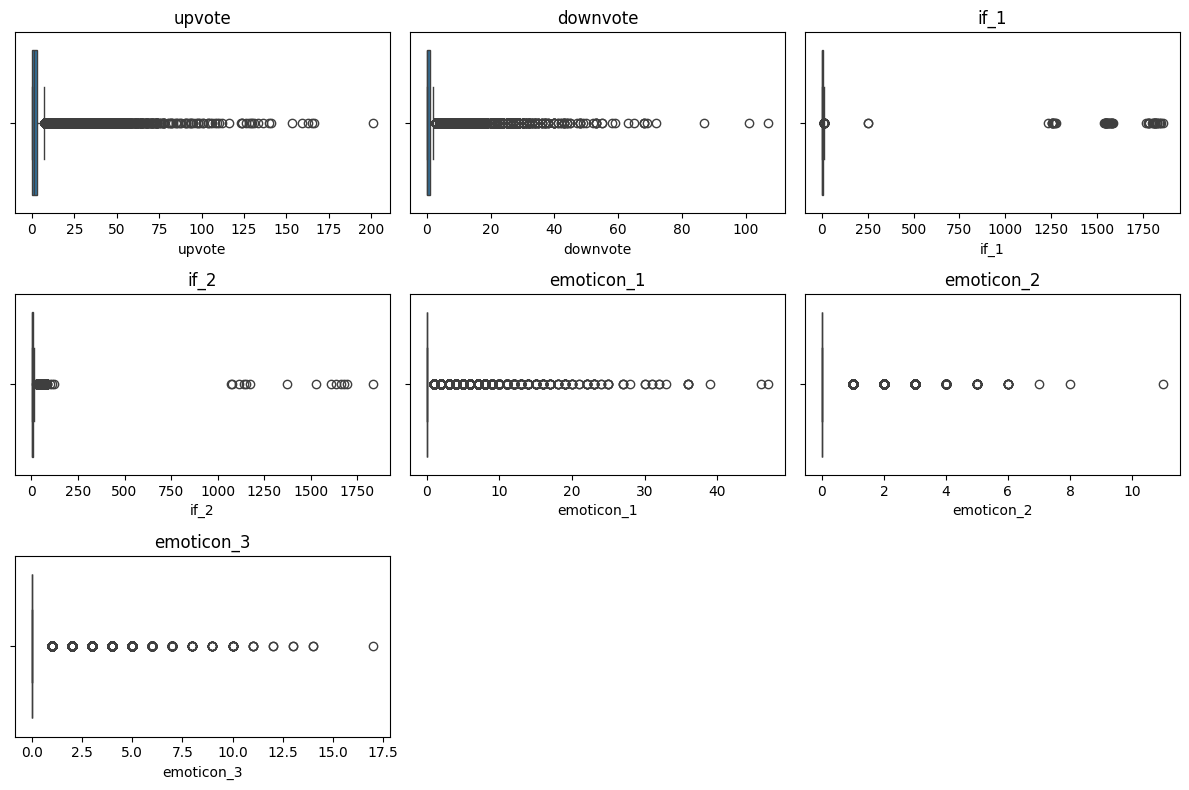

In [17]:
plt.figure(figsize=(12,8))
for i, col in enumerate(numeric_cols):
    plt.subplot(3,3,i+1)
    sns.boxplot(x=train_df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

### 3.4.6 Correlation Heatmap

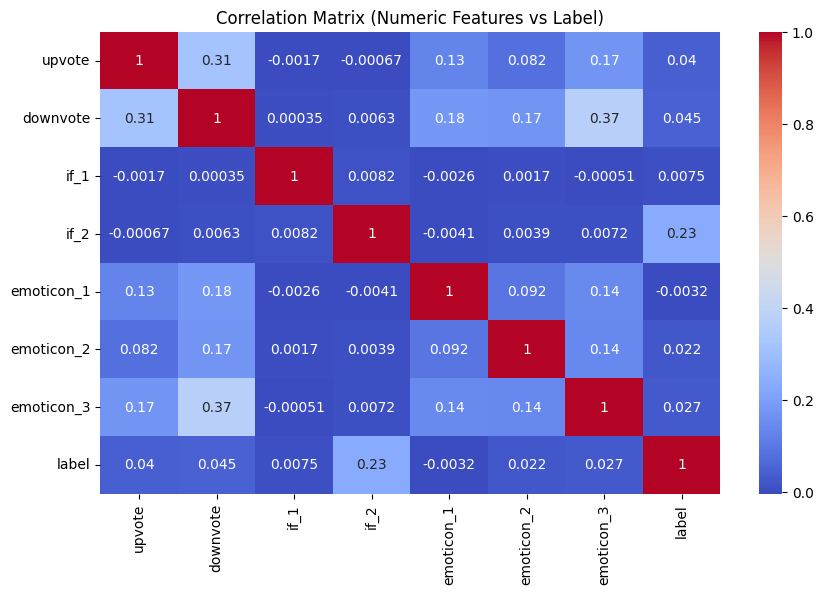

In [18]:
plt.figure(figsize=(10,6))
sns.heatmap(
    train_df[numeric_cols + ["label"]].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Matrix (Numeric Features vs Label)")
plt.show()

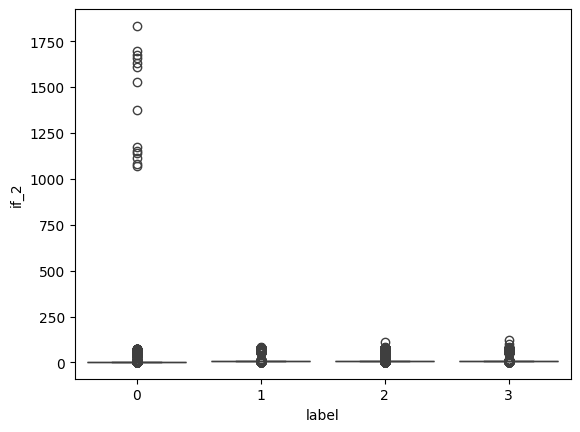

In [19]:
"""
Boxplot of label vs if_2 since if_2 had high correlation. But it seems that was driven by the outliers present in class 0
"""

sns.boxplot(x="label", y="if_2", data=train_df)
plt.show()

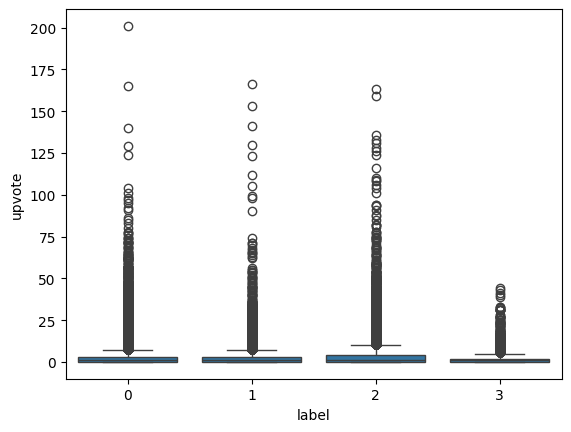

In [20]:
"""
Boxplot of label vs upvote
"""

sns.boxplot(x="label", y="upvote", data=train_df)
plt.show()

# 4. Handling outliers

In [21]:
import numpy as np

def detect_outliers_iqr(df, columns):
    outlier_summary = {}

    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = df[(df[col] < lower) | (df[col] > upper)]
        outlier_summary[col] = len(outliers)

    return outlier_summary

num_cols = ['upvote', 'downvote','if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3']  
outliers = detect_outliers_iqr(train_df, num_cols)

for col, count in outliers.items():
    print(f"Column name: {col} | Number of outliers: {count}")

Column name: upvote | Number of outliers: 17304
Column name: downvote | Number of outliers: 15173
Column name: if_1 | Number of outliers: 85
Column name: if_2 | Number of outliers: 3930
Column name: emoticon_1 | Number of outliers: 28922
Column name: emoticon_2 | Number of outliers: 8109
Column name: emoticon_3 | Number of outliers: 17165


``` 
We analyzed outliers using IQR. However, since features like upvotes represent real engagement, we chose not to remove them. Instead, we rely on scaling/log transformation if needed.
```

# 5. Handling missing values

In [22]:
train_df.isna().sum()

created_date           0
post_id                0
emoticon_1             0
emoticon_2             0
emoticon_3             0
upvote                 0
downvote               0
if_1                   0
if_2                   0
race              145423
religion          145423
gender            145423
disability             0
comment                1
label                  0
comment_length         0
word_count             0
dtype: int64

In [23]:
train_df["race"] = train_df["race"].fillna("unknown")
train_df["religion"] = train_df["religion"].fillna("unknown")
train_df["gender"] = train_df["gender"].fillna("unknown")
train_df["comment"] = train_df["comment"].fillna("")

train_df.isna().sum()

created_date      0
post_id           0
emoticon_1        0
emoticon_2        0
emoticon_3        0
upvote            0
downvote          0
if_1              0
if_2              0
race              0
religion          0
gender            0
disability        0
comment           0
label             0
comment_length    0
word_count        0
dtype: int64

# 6. Data preprocesing

In [24]:
train_df.head()

,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label,comment_length,word_count
0,2024-01-18 08:43:57.397508+00:00,73,0,0,0,0,1,0,10,unknown,unknown,unknown,False,She might be a bright spot for a party keou on...,2,118,20
1,2024-03-24 21:43:11.490017+00:00,39,0,0,0,6,0,0,4,unknown,unknown,unknown,False,"Under Alaska law, a non-tribal member is not b...",0,644,110
2,2024-04-24 20:32:17.014931+00:00,31,0,1,1,0,0,0,10,unknown,unknown,unknown,False,in the future please spare me your strawman dr...,2,751,133
3,2023-05-28 22:00:14.214527+00:00,39,0,0,0,5,0,0,10,unknown,unknown,unknown,False,"PS: That should have been ""rot"" instead of ""co...",2,91,15
4,2023-09-09 23:12:05.689498+00:00,39,0,0,0,0,0,0,10,unknown,unknown,unknown,False,"Today, the confederate flag...tomorrow, the na...",2,254,40


In [25]:
# --- Engagement engineered features ---
train_df["engagement_total"] = train_df["upvote"] + train_df["downvote"]
train_df["engagement_diff"] = train_df["upvote"] - train_df["downvote"]
train_df["engagement_ratio"] = train_df["upvote"] / (train_df["downvote"] + 1)

test_df["engagement_total"] = test_df["upvote"] + test_df["downvote"]
test_df["engagement_diff"] = test_df["upvote"] - test_df["downvote"]
test_df["engagement_ratio"] = test_df["upvote"] / (test_df["downvote"] + 1)


train_df = train_df.drop(columns=["created_date", "post_id", "comment_length", "word_count"], errors="ignore")
test_df = test_df.drop(columns=["created_date", "post_id", "comment_length", "word_count"], errors="ignore")

In [26]:
"""
Grouping features based on their type to apply appropriate preprocessing techniques such as scaling, encoding, and transformation.
"""

text_col = ["comment"]

numeric_log_cols = [
    "upvote", "downvote",
    "engagement_total",
    "engagement_ratio"
]

numeric_no_log_cols = [
    "engagement_diff",
    "if_1", "if_2",
    "emoticon_1", "emoticon_2", "emoticon_3"
]

categorical_cols = ["race", "religion", "gender", "disability"]


In [27]:
preprocessor = ColumnTransformer(
    transformers=[

        # TEXT
        (
            "text",
            Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value="")),
                ("squeeze", FunctionTransformer(lambda x: x.squeeze(), validate=False)),
                ("tfidf", TfidfVectorizer(
                    max_features=20000,
                    ngram_range=(1,2),
                    min_df=5,
                    max_df=0.9,
                    sublinear_tf=True,
                    stop_words="english"
                ))
            ]),
            text_col
        ),

        # NUMERIC WITH LOG 
        (
            "num_log",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("log", FunctionTransformer(np.log1p, validate=False)),
                ("scaler", RobustScaler())
            ]),
            numeric_log_cols
        ),

        # NUMERIC WITHOUT LOG
        (
            "num_no_log",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", RobustScaler())
            ]),
            numeric_no_log_cols
        ),

        # CATEGORICAL
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols
        )
    ]
)

In [28]:
"""
Train Test Split
"""

# train_df = train_df.drop(columns=["created_date", "post_id", "comment_length", "word_count"])

X = train_df.drop("label", axis=1)
y = train_df["label"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [29]:
print(X_train.shape, X_val.shape , y_train.shape , y_val.shape)

(158400, 15) (39600, 15) (158400,) (39600,)


# 7. Models

## 7.1 Logistic regression

In [30]:
log_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        C=1.0,                     
        penalty="l2",
        solver="lbfgs",
        max_iter=8000,
        n_jobs=-1,
        class_weight={0:1, 1:1.5, 2:1, 3:2.5} 
    ))
])


In [31]:
log_model.fit(X_train, y_train)
y_pred_log = log_model.predict(X_val)

print(classification_report(y_val, y_pred_log))

              precision    recall  f1-score   support

           0       0.97      0.94      0.96     22835
           1       0.76      0.78      0.77      3183
           2       0.86      0.90      0.88     12488
           3       0.64      0.61      0.63      1094

    accuracy                           0.91     39600
   macro avg       0.81      0.81      0.81     39600
weighted avg       0.91      0.91      0.91     39600



In [32]:
macro_f1_log = f1_score(y_val, y_pred_log, average="macro")
print("Macro F1:", macro_f1_log)

Macro F1: 0.8071391608439032


## 7.2 Linear SVC

In [33]:
from sklearn.svm import LinearSVC

svc_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        max_iter=5000
    ))
])

svc_model.fit(X_train, y_train)

y_pred_svc = svc_model.predict(X_val)

print(classification_report(y_val, y_pred_svc))

              precision    recall  f1-score   support

           0       0.85      0.85      0.85     22835
           1       0.62      0.73      0.67      3183
           2       0.78      0.71      0.75     12488
           3       0.42      0.57      0.48      1094

    accuracy                           0.79     39600
   macro avg       0.67      0.72      0.69     39600
weighted avg       0.80      0.79      0.79     39600



In [34]:
macro_f1_svc = f1_score(y_val, y_pred_svc, average="macro")
print("Macro F1:", macro_f1_svc)

Macro F1: 0.687515000820194


## 7.3 Ridge Classifier

In [35]:
from sklearn.linear_model import RidgeClassifier

ridge_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RidgeClassifier(class_weight={0:1, 1:1.5, 2:1, 3:2.5}))
])

ridge_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_val)

print(classification_report(y_val, y_pred_ridge))

              precision    recall  f1-score   support

           0       0.80      0.90      0.85     22835
           1       0.69      0.67      0.68      3183
           2       0.81      0.64      0.72     12488
           3       0.56      0.45      0.50      1094

    accuracy                           0.79     39600
   macro avg       0.72      0.67      0.69     39600
weighted avg       0.79      0.79      0.78     39600



In [36]:
macro_f1 = f1_score(y_val, y_pred_ridge, average="macro")
print("Macro F1:", macro_f1)

Macro F1: 0.6863200734148606


## 7.4 SGD Classifier (log loss)

In [37]:
from sklearn.linear_model import SGDClassifier

sgd_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", SGDClassifier(
        loss="log_loss",
        class_weight={0:1, 1:1.5, 2:1, 3:2.5},
        max_iter=2000,
        tol=1e-3
    ))
])

sgd_model.fit(X_train, y_train)

y_pred_sgd = sgd_model.predict(X_val)

print(classification_report(y_val, y_pred_sgd))

              precision    recall  f1-score   support

           0       0.96      0.94      0.95     22835
           1       0.69      0.68      0.69      3183
           2       0.80      0.89      0.84     12488
           3       0.80      0.19      0.31      1094

    accuracy                           0.88     39600
   macro avg       0.81      0.68      0.70     39600
weighted avg       0.88      0.88      0.88     39600



In [38]:
macro_f1_sgd = f1_score(y_val, y_pred_sgd, average="macro")
print("Macro F1:", macro_f1_sgd)

Macro F1: 0.6978061402171796


## 7.5 LightGBM model

In [39]:
import lightgbm as lgb

lgb_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", lgb.LGBMClassifier(
        n_estimators=300,
        class_weight={0:1, 1:1.5, 2:1, 3:2.5},
        random_state=42
    ))
])

lgb_model.fit(X_train, y_train)

y_pred_lgb = lgb_model.predict(X_val)

print(classification_report(y_val, y_pred_lgb))
macro_f1 = f1_score(y_val, y_pred_lgb, average="macro")
print("Macro F1:", macro_f1)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 24.496241 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 881417
[LightGBM] [Info] Number of data points in the train set: 158400, number of used features: 19959
[LightGBM] [Info] Start training from score -0.629025
[LightGBM] [Info] Start training from score -2.193772
[LightGBM] [Info] Start training from score -1.232529
[LightGBM] [Info] Start training from score -2.751394


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


              precision    recall  f1-score   support

           0       0.98      0.95      0.96     22835
           1       0.75      0.81      0.78      3183
           2       0.87      0.90      0.88     12488
           3       0.67      0.62      0.64      1094

    accuracy                           0.91     39600
   macro avg       0.82      0.82      0.82     39600
weighted avg       0.92      0.91      0.91     39600

Macro F1: 0.8167566162128042


# 8. Hyper-parameter tuning

### Note:
The model choosen for hyper parameter training is Logistic Regression and not LightGBM despite lightGBM being the best model.
I am woking on tuning the preprocessor in order to be able to tune LightGBM properly.

In [40]:
"""
Preprocessing before hyper parameter tuning so the models can predict without preprocessing everytime.
"""
preprocessor.fit(X_train)

X_train_transformed = preprocessor.transform(X_train)
X_val_transformed = preprocessor.transform(X_val)

In [41]:
print(X_train_transformed.shape)
print(X_val_transformed.shape)

(158400, 20034)
(39600, 20034)


In [42]:
from sklearn.linear_model import LogisticRegression

base_model = LogisticRegression(
    max_iter=8000,
    n_jobs=-1
)

In [43]:
param_dist = {
    "C": [0.5, 1.0],
    "solver": ["lbfgs", "saga"],
    "class_weight": [
        None,
        {0:1, 1:1.5, 2:1, 3:2.5}
    ]
}


In [44]:
from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(
    base_model,
    param_distributions=param_dist,
    n_iter=5,
    scoring="f1_macro",
    cv=2,
    verbose=2,
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train_transformed, y_train)

Fitting 2 folds for each of 5 candidates, totalling 10 fits
[CV] END ..............C=1.0, class_weight=None, solver=saga; total time=25.7min
[CV] END C=0.5, class_weight={0: 1, 1: 1.5, 2: 1, 3: 2.5}, solver=lbfgs; total time=  55.9s
[CV] END ..............C=1.0, class_weight=None, solver=saga; total time=24.9min
[CV] END .............C=0.5, class_weight=None, solver=lbfgs; total time= 1.3min
[CV] END C=0.5, class_weight={0: 1, 1: 1.5, 2: 1, 3: 2.5}, solver=lbfgs; total time= 1.2min


RandomizedSearchCV(cv=2, estimator=LogisticRegression(max_iter=8000, n_jobs=-1),
                   n_iter=5, n_jobs=-1,
                   param_distributions={'C': [0.5, 1.0],
                                        'class_weight': [None,
                                                         {0: 1, 1: 1.5, 2: 1,
                                                          3: 2.5}],
                                        'solver': ['lbfgs', 'saga']},
                   random_state=42, scoring='f1_macro', verbose=2)

In [45]:
print("Best Params:", random_search.best_params_)
print("Best CV Score:", random_search.best_score_)

Best Params: {'solver': 'lbfgs', 'class_weight': {0: 1, 1: 1.5, 2: 1, 3: 2.5}, 'C': 0.5}
Best CV Score: 0.7953213408725374


In [46]:
from sklearn.metrics import f1_score

best_model = random_search.best_estimator_

y_pred = best_model.predict(X_val_transformed)

print("Best Params:", random_search.best_params_)
print("Macro F1:", f1_score(y_val, y_pred, average="macro"))

Best Params: {'solver': 'lbfgs', 'class_weight': {0: 1, 1: 1.5, 2: 1, 3: 2.5}, 'C': 0.5}
Macro F1: 0.8086226437348871


# 9. Model Comparison

In [47]:
data = {
    'Model': ['Logistic Regression', 'Linear SVC', 'Ridge Classifier', 'SGD Classifier', 'LightGBM' , 'Tuned Logistic Regression'],
    'Macro_f1': [0.8071, 0.6875, 0.6863, 0.7035 , 0.8168, 0.8086]
}

results_df = pd.DataFrame(data)
print(results_df)


                       Model  Macro_f1
0        Logistic Regression    0.8071
1                 Linear SVC    0.6875
2           Ridge Classifier    0.6863
3             SGD Classifier    0.7035
4                   LightGBM    0.8168
5  Tuned Logistic Regression    0.8086


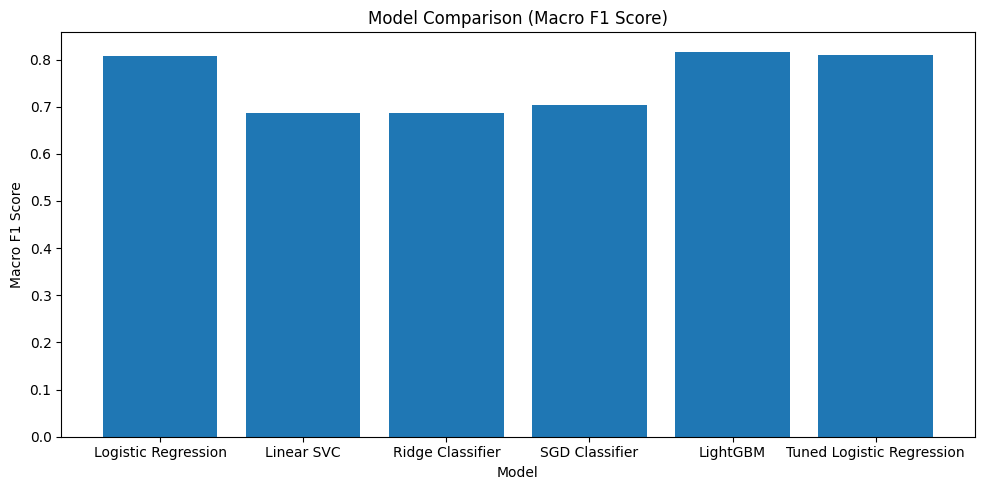

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["Macro_f1"])

plt.title("Model Comparison (Macro F1 Score)")
plt.xlabel("Model")
plt.ylabel("Macro F1 Score")

plt.tight_layout()
plt.show()

### Model Comparison

* Multiple machine learning models were trained and evaluated using the Macro F1-score to ensure balanced performance across all classes.
* LightGBM achieved the highest score.
* Logistic Regression performed competitively yet it fell behind LightGBM.
* SGD Classifier, Linear SVC and Ridge Classifier performed poorly.

### Insights and Learnings
1. LightGBM performed the best given its baseline version which might a direct result of how it handles non linear data. Tree based models have an edge over linear models due to their ability to capture non-linear relationships effectively.
2. Logistic Regression performed good. It's strong score of 0.80 shows that the data might be linearly separable. It shows that the TF-IDF features are highly informative.
3. Hyper parameter tuning improved the f1 score but not by much since the baseline was already strong enough.
4. Linear SVC and Ridge Classifier performed worse due to the following reasons:
     * Inability to capture complex relationships
     * Sensitivity to feature scaling and high dimensionality


# Submission

In [49]:
text_col = ["comment"]

numeric_log_cols = [
    "upvote", "downvote",
    "if_1", "if_2",
    "emoticon_1", "emoticon_2", "emoticon_3",
    "engagement_total",
    "engagement_ratio"
]

numeric_no_log_cols = [
    "engagement_diff"
]

categorical_cols = ["race", "religion", "gender", "disability"]

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

submission_preprocessor = ColumnTransformer(
    transformers=[
        
        # WORD TF-IDF
        (
            "word_tfidf",
            Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value="")),
                ("squeeze", FunctionTransformer(lambda x: x.squeeze(), validate=False)),
                ("tfidf", TfidfVectorizer(
                    analyzer="word",
                    ngram_range=(1,4),
                    max_features=15000,
                    min_df=5,
                    max_df=0.9,
                    sublinear_tf=True,
                    stop_words="english"
                ))
            ]),
            text_col
        ),
        
        # CHAR TF-IDF
        (
            "char_tfidf",
            Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value="")),
                ("squeeze", FunctionTransformer(lambda x: x.squeeze(), validate=False)),
                ("tfidf", TfidfVectorizer(
                    analyzer="char_wb",
                    ngram_range=(3,5),
                    max_features=20000,
                    min_df=5,
                    sublinear_tf=True
                ))
            ]),
            text_col
        ),
        
        # LOG NUMERIC
        (
            "num_log",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("log", FunctionTransformer(np.log1p, validate=False)),
                ("scaler", RobustScaler())
            ]),
            numeric_log_cols
        ),
        
        # NON-LOG NUMERIC
        (
            "num_no_log",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", RobustScaler())
            ]),
            numeric_no_log_cols
        ),
        
        # CATEGORICAL
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols
        )
    ]
)

In [50]:
final_model = Pipeline([
    ("preprocessing", submission_preprocessor),
    ("classifier", LogisticRegression(
        C=0.5,
        penalty="l2",
        solver="saga",
        max_iter=8000,
        class_weight={0:1, 1:1.5, 2:1, 3:2.5},
        n_jobs=-1
    ))
])

final_model.fit(X, y)

[CV] END ..............C=0.5, class_weight=None, solver=saga; total time=24.4min
[CV] END .............C=0.5, class_weight=None, solver=lbfgs; total time=  50.9s
[CV] END C=1.0, class_weight={0: 1, 1: 1.5, 2: 1, 3: 2.5}, solver=saga; total time=13.2min
[CV] END ..............C=0.5, class_weight=None, solver=saga; total time=25.0min
[CV] END C=1.0, class_weight={0: 1, 1: 1.5, 2: 1, 3: 2.5}, solver=saga; total time=13.0min


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('word_tfidf',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='',
                                                                                 strategy='constant')),
                                                                  ('squeeze',
                                                                   FunctionTransformer(func=<function <lambda> at 0x7af7a7699b20>)),
                                                                  ('tfidf',
                                                                   TfidfVectorizer(max_df=0.9,
                                                                                   max_features=15000,
                                                                                   min_df=5,
                                                                                   ngram_range=(1,
                                                                                                4),
                                                                                   stop_words='english',
                                                                                   sublinear_tf=True)...
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['engagement_diff']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='unknown',
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['race', 'religion', 'gender',
                                                   'disability'])])),
                ('classifier',
                 LogisticRegression(C=0.5,
                                    class_weight={0: 1, 1: 1.5, 2: 1, 3: 2.5},
                                    max_iter=8000, n_jobs=-1, solver='saga'))])

In [51]:
test_predictions = final_model.predict(test_df)


submission = sample_sub.copy()
submission["label"] = test_predictions

submission.to_csv("submission.csv", index=False)

In [52]:
print(submission.head(2))
print(sample_sub.head(2))

   ID  label
0   1      2
1   2      2
   ID  label
0   1      0
1   2      0


# Key Learnings and Insights from the Project

## 🔹 1. Importance of Text Feature Extraction
- TF-IDF proved to be highly effective for converting textual data into meaningful numerical representations  
- High-dimensional sparse features enabled strong performance even with simple models like Logistic Regression
- A good combination of char and word tfidf is better than either one.

## 🔹 2. Feature Engineering Improves Signal Quality
- Engagement-based features (total, difference, ratio) helped capture user interaction patterns  
- These engineered features provided additional context beyond raw data  

## 🔹 3. Handling Skewed Data is Crucial
- Numerical features like upvote and downvote were highly skewed  
- Applying log transformation and robust scaling improved model stability  

## 🔹 4. Linear Models Perform Strongly on Text Data
- Logistic Regression achieved strong performance (~0.80+)  
- This shows that:
  - TF-IDF features make data nearly linearly separable  
  - Simple models can perform well with good feature representation  

## 🔹 5. Tree-Based Models Capture Complex Patterns
- LightGBM outperformed all models  
- It was able to:
  - Capture non-linear relationships  
  - Model feature interactions effectively  

## 🔹 6. Hyperparameter Tuning Provides Incremental Gains
- Tuning improved model performance slightly  
- However, large gains came from:
  - Feature engineering  
  - Preprocessing  

## 🔹 7. Importance of Proper Evaluation Metrics
- Macro F1-score ensured fair evaluation across all classes  
- This was important due to the extreme class imbalance found in the dataset.

## 🔹 8. Pipelines Improve Reproducibility
- Using pipelines ensured:
  - Consistent preprocessing  
  - No data leakage  
  - Clean and maintainable code  